# MLM concordance without proliferation pathways

Cell lines are selected for growth in culture, and the tumor atlas is
dominated by proliferative states. This notebook repeats the MLM
concordance after removing the shared cell-cycle and proliferation
Hallmark terms (`E2F_TARGETS`, `G2M_CHECKPOINT`, `MITOTIC_SPINDLE`,
`MYC_TARGETS_V1`, `MYC_TARGETS_V2`).

The per-cell scores come from notebooks 4 and 5; nothing is rescored
here.

In [1]:
from pathlib import Path
import sys

import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.bio import matching, mlm, plots
from src.utils import load_config

cfg = load_config()
paths = cfg["paths"]
bio = cfg.get("bio", {})
FIG_DIR = ROOT / paths["bio"]["figures"]
FIG_DIR.mkdir(parents=True, exist_ok=True)

K_MATCHING = int(bio.get("matching", {}).get("k", 50))
MARGIN = float(bio.get("matching", {}).get("margin", 0.10))

## Inputs

The joint artifact supplies the matching frame. The three MLM score
artifacts come from notebooks 4 and 5.

In [2]:
combined = ad.read_h5ad(ROOT / paths["bio"]["joint_artifact"])
settings = combined.uns["bio_leiden_settings"]
tumor_res = float(settings["tumor_res"])
tumor_key = f"tumor_leiden_res{tumor_res}"

de_dir = ROOT / paths["bio"]["de_joint"]
sens_dir = de_dir / "hallmark_mlm_sensitivity"
score_paths = {
    "hvg_corrected": sens_dir / "mlm_scores_hvg_corrected.h5ad",
    "hvg_uncorrected": sens_dir / "mlm_scores_hvg_uncorrected.h5ad",
    "full_uncorrected": de_dir / "hallmark_mlm" / "hallmark_mlm_scores.h5ad",
}
for path in score_paths.values():
    assert path.exists(), f"missing cached MLM scores: {path}"

group = matching.make_match_groups(combined.obs, tumor_key)
_, line_matches, _, tumor_order = matching.match_lines(
    combined.obsm["X_latent"], group, combined.obs, K_MATCHING, margin=MARGIN
)
line_order = [str(line).replace("line_", "") for line in matching.line_order(line_matches)]
line_matches = line_matches.loc[line_order]
print(f"{len(line_order)} cell lines; {len(tumor_order)} tumor subpopulations")

10 cell lines; 18 tumor subpopulations


## Shared pathway set

The three representations support different numbers of Hallmark terms at
`tmin=15`. The paired comparison uses the intersection (45 terms) and
drops the proliferation terms from that shared set (41 terms).

In [3]:
scores_by_representation = {}
obs_by_representation = {}
n_genes_by_representation = {}
for label, path in score_paths.items():
    scores, obs, artifact = mlm.load_scores(path)
    scores_by_representation[label] = scores
    obs_by_representation[label] = obs
    n_genes_by_representation[label] = int(artifact.uns["mlm_manifest"]["n_genes"])
    print(f"{label}: {scores.shape[0]} cells x {scores.shape[1]} pathways")

shared_pathways = sorted(
    set.intersection(*(set(scores.columns) for scores in scores_by_representation.values()))
)
shared_noprolif = [
    pathway
    for pathway in shared_pathways
    if pathway not in set(mlm.PROLIFERATION_PATHWAYS)
]
print(f"shared pathways: {len(shared_pathways)} -> {len(shared_noprolif)} without proliferation")
print(
    "proliferation terms removed from shared set:",
    [p for p in mlm.PROLIFERATION_PATHWAYS if p in shared_pathways],
)

hvg_corrected: 110293 cells x 45 pathways


hvg_uncorrected: 110293 cells x 45 pathways


full_uncorrected: 110293 cells x 50 pathways
shared pathways: 45 -> 41 without proliferation
proliferation terms removed from shared set: ['E2F_TARGETS', 'G2M_CHECKPOINT', 'MITOTIC_SPINDLE', 'MYC_TARGETS_V1']


## Concordance with and without proliferation

The all-pathway matrix is computed on the 45 shared terms so the
comparison is paired; the no-proliferation matrix drops the proliferation
terms from that set. The comparison figure is saved under
`figures/BIOVAL/`.

In [4]:
all_pathway = {}
no_prolif = {}
for label in score_paths:
    all_pathway[label] = mlm.concordance_matrix(
        scores_by_representation[label],
        obs_by_representation[label],
        line_order,
        tumor_order,
        pathways=shared_pathways,
    )
    no_prolif[label] = mlm.concordance_matrix(
        scores_by_representation[label],
        obs_by_representation[label],
        line_order,
        tumor_order,
        pathways=shared_noprolif,
    )

print("computed concordance matrices for", list(score_paths))

computed concordance matrices for ['hvg_corrected', 'hvg_uncorrected', 'full_uncorrected']


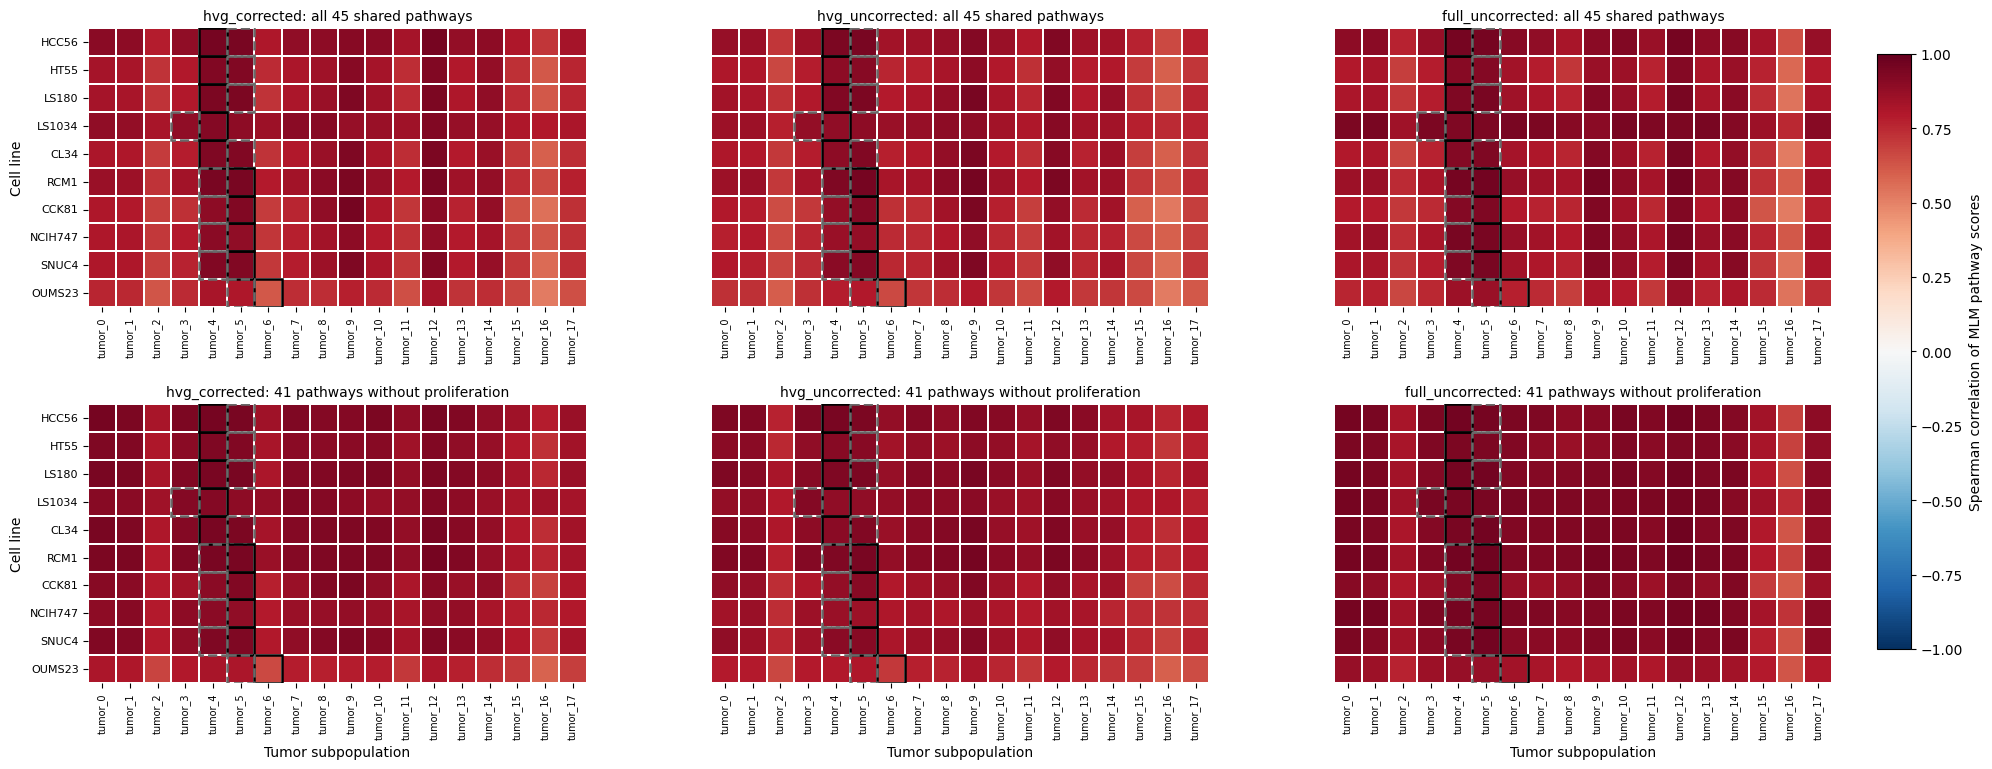

In [5]:
plots.plot_noprolif_comparison(
    all_pathway,
    no_prolif,
    line_matches,
    len(shared_pathways),
    len(shared_noprolif),
    path=FIG_DIR / "mlm_concordance_noprolif_comparison.png",
)
plt.show()

## Summary

The table reports the median line-subpopulation correlation, the number of
lines whose primary candidate beats the runner-up, and the stability of
the matrix relative to the all-pathway version. The final summary is
saved; the per-line table stays in the notebook.

In [6]:
rows = []
for label in score_paths:
    matrix = no_prolif[label]
    old = all_pathway[label]
    deltas_new = np.array(
        [
            matrix.loc[line, line_matches.loc[line, "primary_match"]]
            - matrix.loc[line, line_matches.loc[line, "second_match"]]
            for line in line_order
        ]
    )
    deltas_old = np.array(
        [
            old.loc[line, line_matches.loc[line, "primary_match"]]
            - old.loc[line, line_matches.loc[line, "second_match"]]
            for line in line_order
        ]
    )
    top1_new = sum(
        matrix.loc[line].idxmax() == line_matches.loc[line, "primary_match"]
        for line in line_order
    )
    rows.append(
        {
            "representation": label,
            "n_genes": n_genes_by_representation[label],
            "n_pathways": len(shared_noprolif),
            "median_rho": float(np.nanmedian(matrix.to_numpy())),
            "min_rho": float(np.nanmin(matrix.to_numpy())),
            "n_lines_primary_gt_runner_up": int((deltas_new > 0).sum()),
            "n_primary_top1": int(top1_new),
            "median_primary_minus_runner_up": float(np.median(deltas_new)),
            "median_delta_vs_all_pathways": float(np.median(deltas_new - deltas_old)),
            "spearman_vs_all_pathways": float(
                pd.Series(matrix.to_numpy().ravel()).corr(
                    pd.Series(old.to_numpy().ravel()), method="spearman"
                )
            ),
        }
    )
summary = pd.DataFrame(rows).set_index("representation")
summary.to_csv(sens_dir / "summary_no_proliferation.csv")
display(summary.round(3))

print("Cross-representation Spearman correlation (without proliferation):")
display(mlm.cross_representation_correlations(no_prolif).round(3))

,n_genes,n_pathways,median_rho,min_rho,n_lines_primary_gt_runner_up,n_primary_top1,median_primary_minus_runner_up,median_delta_vs_all_pathways,spearman_vs_all_pathways
representation,,,,,,,,,
hvg_corrected,1135,41,0.887,0.586,6,4,0.002,-0.001,0.852
hvg_uncorrected,1135,41,0.859,0.598,5,2,0.001,0.001,0.900
full_uncorrected,4237,41,0.924,0.610,6,4,0.001,0.003,0.851


Cross-representation Spearman correlation (without proliferation):


,hvg_corrected,hvg_uncorrected,full_uncorrected
hvg_corrected,1.000,0.948,0.815
hvg_uncorrected,0.948,1.000,0.810
full_uncorrected,0.815,0.810,1.000


In [7]:
per_line_rows = []
for line in line_order:
    match = line_matches.loc[line]
    row = {
        "cell_line": line,
        "primary_match": match["primary_match"],
        "runner_up": match["second_match"],
    }
    for label in score_paths:
        matrix = no_prolif[label]
        row[f"{label}_primary_rho"] = float(matrix.loc[line, match["primary_match"]])
        row[f"{label}_primary_minus_runner_up"] = float(
            matrix.loc[line, match["primary_match"]]
            - matrix.loc[line, match["second_match"]]
        )
    per_line_rows.append(row)
per_line = pd.DataFrame(per_line_rows).set_index("cell_line")
per_line.round(3)

,primary_match,runner_up,hvg_corrected_primary_rho,hvg_corrected_primary_minus_runner_up,hvg_uncorrected_primary_rho,hvg_uncorrected_primary_minus_runner_up,full_uncorrected_primary_rho,full_uncorrected_primary_minus_runner_up
cell_line,,,,,,,,
HCC56,tumor_4,tumor_5,0.959,0.012,0.947,0.005,0.961,0.004
HT55,tumor_4,tumor_5,0.934,0.008,0.911,0.004,0.942,0.002
LS180,tumor_4,tumor_5,0.949,0.002,0.931,-0.008,0.957,-0.009
LS1034,tumor_4,tumor_3,0.915,-0.004,0.885,-0.032,0.948,-0.005
CL34,tumor_4,tumor_5,0.947,0.004,0.906,-0.019,0.952,-0.010
RCM1,tumor_5,tumor_4,0.947,-0.002,0.946,0.011,0.976,0.009
CCK81,tumor_5,tumor_4,0.924,0.023,0.909,0.028,0.950,0.024
NCIH747,tumor_5,tumor_4,0.884,-0.020,0.858,-0.002,0.956,0.001
SNUC4,tumor_5,tumor_4,0.934,0.001,0.913,0.011,0.961,0.009
